<a href="https://colab.research.google.com/github/mmmaanton-stack/greends-fads-first-project/blob/main/Assignment3_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
kiva_loans = pd.read_csv("/kiva_loans.csv.zip")
kiva_loans.head()

,id,funded_amount,loan_amount,activity,sector,use,country_code,country,region,currency,partner_id,posted_time,disbursed_time,funded_time,term_in_months,lender_count,tags,borrower_genders,repayment_interval,date
0,653051,300.0,300.0,Fruits & Vegetables,Food,"To buy seasonal, fresh fruits to sell.",PK,Pakistan,Lahore,PKR,247.0,2014-01-01 06:12:39+00:00,2013-12-17 08:00:00+00:00,2014-01-02 10:06:32+00:00,12.0,12,NaN,female,irregular,2014-01-01
1,653053,575.0,575.0,Rickshaw,Transportation,to repair and maintain the auto rickshaw used ...,PK,Pakistan,Lahore,PKR,247.0,2014-01-01 06:51:08+00:00,2013-12-17 08:00:00+00:00,2014-01-02 09:17:23+00:00,11.0,14,NaN,"female, female",irregular,2014-01-01
2,653068,150.0,150.0,Transportation,Transportation,To repair their old cycle-van and buy another ...,IN,India,Maynaguri,INR,334.0,2014-01-01 09:58:07+00:00,2013-12-17 08:00:00+00:00,2014-01-01 16:01:36+00:00,43.0,6,"user_favorite, user_favorite",female,bullet,2014-01-01
3,653063,200.0,200.0,Embroidery,Arts,to purchase an embroidery machine and a variet...,PK,Pakistan,Lahore,PKR,247.0,2014-01-01 08:03:11+00:00,2013-12-24 08:00:00+00:00,2014-01-01 13:00:00+00:00,11.0,8,NaN,female,irregular,2014-01-01
4,653084,400.0,400.0,Milk Sales,Food,to purchase one buffalo.,PK,Pakistan,Abdul Hakeem,PKR,245.0,2014-01-01 11:53:19+00:00,2013-12-17 08:00:00+00:00,2014-01-01 19:18:51+00:00,14.0,16,NaN,female,monthly,2014-01-01


# 1 Which five sectors have the highest and lowest total loan amounts?

In [12]:
display(kiva_loans.groupby('sector')['loan_amount'].sum().sort_values(ascending=False).head(5))
display(kiva_loans.groupby('sector')['loan_amount'].sum().sort_values(ascending=True).head(5))

,loan_amount
sector,
Agriculture,143067875.0
Food,121606150.0
Retail,98122900.0
Services,48057450.0
Clothing,37300925.0


,loan_amount
sector,
Wholesale,995200.0
Entertainment,1389150.0
Manufacturing,5447900.0
Construction,6695150.0
Health,9843400.0


Agriculture had the highest total loan amount (143 067 875) and Wholesale had the lowest total loan amount (995 200)

#  2 What is the average loan amount in each of the ten selected sectors and across all ten combined?

In [41]:
from numpy import astype
selected_loans_max=kiva_loans[kiva_loans['sector'].isin(['Agriculture','Food','Retail','Services','Clothing'])]
display(selected_loans_max.groupby('sector')['loan_amount'].mean().round().astype(int))
selected_loans_min=kiva_loans[kiva_loans['sector'].isin(['Wholesale','Entertainment','Manufacturing','Construction','Health' ])]
display(selected_loans_min.groupby('sector')['loan_amount'].mean().round().astype(int))

,loan_amount
sector,
Agriculture,793
Clothing,1139
Food,890
Retail,788
Services,1065


,loan_amount
sector,
Construction,1068
Entertainment,1674
Health,1067
Manufacturing,878
Wholesale,1570


In [34]:
selected_loans=kiva_loans[kiva_loans['sector'].isin(['Agriculture','Food','Retail','Services','Clothing','Wholesale','Entertainment','Manufacturing','Construction','Health'])]
average_loans=selected_loans['loan_amount'].mean()
print(f"Average loan amount accros 10 selected sectors: {average_loans:.0f}")

Average loan amount accros 10 selected sectors: 871


The average loan amount across 10 selected sectors is 871. the highest amount Agriculture has lower average amount 793 than lowest sector Wholesale with average amount 1570

# 3 What is the gender breakdown of borrowers in Agriculture and Wholesale?

sector       borrower_genders
Agriculture  female              261231
             male                113350
             Unknown               1078
Wholesale    female                 597
             male                   335
             Unknown                  8
Name: count, dtype: int64

sector       borrower_genders
Agriculture  female              69.5
             male                30.2
             Unknown              0.3
Wholesale    female              63.5
             male                35.6
             Unknown              0.9
Name: proportion, dtype: float64

,borrower_genders
sector,
Agriculture,0
Wholesale,0


<Axes: ylabel='sector'>

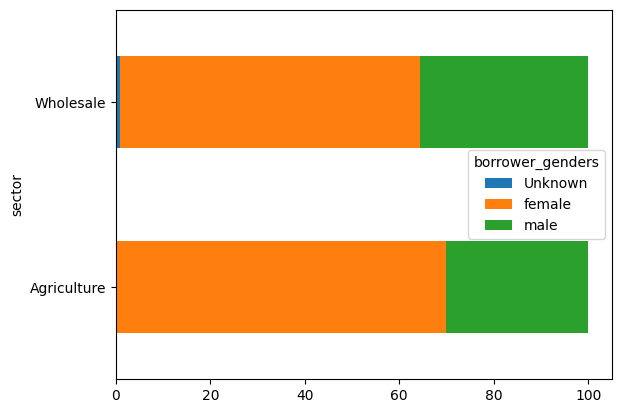

In [63]:
sector_selected=kiva_loans[kiva_loans['sector'].isin(['Agriculture','Wholesale'])].copy()
##display(sector_selected[['sector', 'borrower_genders']].groupby('sector').head(5))
##sector_selected["borrower_genders"].value_counts()
sector_selected["borrower_genders"]=sector_selected["borrower_genders"].str.split(', ')
##display(sector_selected[['sector','borrower_genders']].head(10))
borrowers=sector_selected.explode('borrower_genders').fillna('Unknown')
display(borrowers.groupby('sector')['borrower_genders'].value_counts())
gender_share = borrowers.groupby('sector')['borrower_genders'].value_counts(normalize=True) * 100
display(gender_share.round(1))
display(borrowers.groupby('sector')['borrower_genders'].apply(lambda x: x.isna().sum()))
gender_share.unstack().plot(kind='barh', stacked=True)

Women represent the majority of borrowers with known gender in both sectors: 69.5% in Agriculture and 63.5% in Wholesale. Unknown gender accounts for 0.3% and 0.9%, respectively.

# 4. Which countries are the borrowers from for Agriculture and Wholesale?

np.int64(0)

,country
sector,
Agriculture,78
Wholesale,54


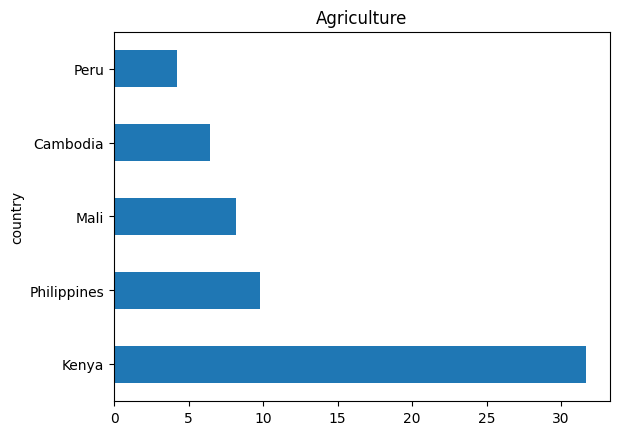

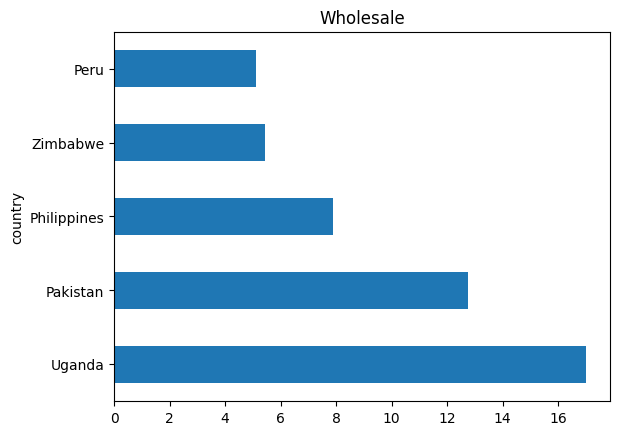

In [96]:
sector_selected=kiva_loans[kiva_loans['sector'].isin(['Agriculture','Wholesale'])]
display(borrowers['country'].isna().sum())
display(borrowers.groupby('sector')['country'].nunique())
country_share = borrowers.groupby('sector')['country'].value_counts(normalize=True) *100

import matplotlib.pyplot as plt

country_share['Agriculture'].head(5).plot(kind='barh', title='Agriculture')
plt.show()

country_share['Wholesale'].head(5).plot(kind='barh', title='Wholesale')
plt.show()



The Agriculture sector has a wider geographical distribution, covering 78 countries compared to 54 in Wholesale. Kenya is the leading country in Agriculture (31.7%), while Uganda leads in Wholesale (17.0% based on 160 out of 940 records). The Philippines and Peru are among the top five countries in both sectors. No missing country values were found.

# 5. How does the distribution of loan sizes differ between Agriculture and Wholesale?

In [84]:
display(sector_selected.groupby('sector')['loan_amount'].agg(['min', 'max', 'mean', 'median']))
def size_class(a):
    if a < 500:
        return 'Small'
    elif a < 1000:
        return 'Medium'
    else:
        return 'Large'
sector_selected = sector_selected.copy()

sector_selected['loan_size'] = sector_selected['loan_amount'].apply(size_class)
display(sector_selected.groupby('sector')['loan_size'].value_counts())
display(sector_selected['loan_amount'].isna().sum())
size_share = sector_selected.groupby('sector')['loan_size'].value_counts(normalize=True) * 100

display(size_share.round(1))

,min,max,mean,median
sector,,,,
Agriculture,25.0,100000.0,793.490228,500.0
Wholesale,50.0,50000.0,1569.716088,950.0


sector       loan_size
Agriculture  Small        83999
             Medium       49575
             Large        46728
Wholesale    Large          305
             Small          174
             Medium         155
Name: count, dtype: int64

np.int64(0)

sector       loan_size
Agriculture  Small        46.6
             Medium       27.5
             Large        25.9
Wholesale    Large        48.1
             Small        27.4
             Medium       24.4
Name: proportion, dtype: float64

Small loans are the most common in Agriculture (46.6%), while large loans are the most common in Wholesale (48.1%). The median loan amount is also higher in Wholesale (USD 950)    than  in Agriculture (USD 500). This helps explain the higher average loan amount in the Wholesale sector.

# 6. How successful is loan funding in Agriculture compared to Wholesale?

In [95]:
sector_selected['funding_percentage'] = sector_selected['funded_amount'] / sector_selected['loan_amount'] * 100
display(sector_selected.groupby('sector')['funding_percentage'].agg(['min', 'max', 'mean', 'median']).round(1))

overfunded = sector_selected[sector_selected['funding_percentage'] > 100]

display(overfunded[['sector', 'loan_amount', 'funded_amount', 'funding_percentage']])
display(len(overfunded))
display(sector_selected['funding_percentage'].isna().sum())
def funding_status(a):
    if a == 0:
        return 'Not funded'
    elif a < 100:
        return 'Partially funded'
    elif a == 100:
        return 'Fully funded'
    else:
        return 'Overfunded'
sector_selected['funding_status'] = sector_selected['funding_percentage'].apply(funding_status)
display(sector_selected.groupby('sector')['funding_status'].value_counts())
funding_share = sector_selected.groupby('sector')['funding_status'].value_counts(normalize=True) * 100

display(funding_share.round(1))

,min,max,mean,median
sector,,,,
Agriculture,0.0,113.3,95.8,100.0
Wholesale,0.0,100.0,98.6,100.0


,sector,loan_amount,funded_amount,funding_percentage
338159,Agriculture,3000.0,3400.0,113.333333


1

np.int64(0)

sector       funding_status  
Agriculture  Fully funded        166500
             Partially funded     13138
             Not funded             663
             Overfunded               1
Wholesale    Fully funded           613
             Partially funded        20
             Not funded               1
Name: count, dtype: int64

sector       funding_status  
Agriculture  Fully funded        92.3
             Partially funded     7.3
             Not funded           0.4
             Overfunded           0.0
Wholesale    Fully funded        96.7
             Partially funded     3.2
             Not funded           0.2
Name: proportion, dtype: float64

Wholesale has a higher average funding percentage than Agriculture (98.6% compared to 95.8%), despite having larger loan amounts. The proportion of fully funded loans is also higher in Wholesale (96.7% compared to 92.3%). One overfunded loan (113.3%) was identified in Agriculture and retained in the analysis.
